# Prácticas de Investigación de Operaciones
## Fecha de entrega: 19 de noviembre de 2026
## Equipo: [Luis Angel Garcia, Sergio Manuel Martinez , Diego Uriel Dominguez ]
## Materia: Investigación de Operaciones

### Contenido
1. Identificación de nodos y arcos
2. Árbol de expansión mínima (Kruskal)
3. Ruta crítica (CPM)
4. Algoritmo de Dijkstra
5. Conclusiones


## 0. Configuración inicial

Antes de comenzar, importamos las librerías necesarias:
- **networkx**: para crear y manipular grafos.
- **matplotlib**: para generar las visualizaciones paso a paso.
- **numpy**: para operaciones numéricas auxiliares.

Configuramos también el estilo de las gráficas para que todas se vean uniformes.

In [7]:
import networkx as nx
import matplotlib.pyplot as plt
import numpy as np

# Estilo uniforme para todas las gráficas
plt.rcParams['figure.dpi'] = 100
plt.rcParams['font.size'] = 11

# Semilla para que las posiciones de los nodos sean reproducibles
SEED = 42

print("✔ Librerías cargadas correctamente")

✔ Librerías cargadas correctamente


## 1.1 ¿Qué es un grafo?

Un **grafo** G = (V, E) está formado por:
- **Nodos (V)**: los puntos o vértices (por ejemplo, ciudades, estaciones, actividades).
- **Arcos (E)**: las conexiones entre nodos (carreteras, cables, dependencias).

Si los arcos tienen **peso** (distancia, costo, tiempo), hablamos de un **grafo ponderado**.

**En esta sección:** definiremos una red de 6 ciudades y mostraremos gráficamente sus nodos y arcos con sus pesos.

### 1.2 Construcción del grafo

Definimos 6 nodos (A–F) y las aristas con sus distancias. Usamos `nx.Graph()` porque la red es **no dirigida** (las carreteras van en ambos sentidos).

In [14]:
# Crear grafo no dirigido
G = nx.Graph()

# Definir nodos
nodos = ['A', 'B', 'C', 'D', 'E', 'F']
G.add_nodes_from(nodos)

# Definir arcos con pesos (distancias en km)
arcos = [
    ('A', 'B', 4), ('A', 'C', 2),
    ('B', 'C', 1), ('B', 'D', 5),
    ('C', 'D', 8), ('C', 'E', 10),
    ('D', 'E', 2), ('D', 'F', 6),
    ('E', 'F', 3)
]
G.add_weighted_edges_from(arcos)

print("Nodos:", list(G.nodes()))
print("Número de arcos:", G.number_of_edges())

Nodos: ['A', 'B', 'C', 'D', 'E', 'F']
Número de arcos: 9


### 1.3 Visualización de la red

Dibujamos el grafo con `spring_layout`, que ubica los nodos de forma que las aristas se crucen lo menos posible. Cada arco muestra su **peso** (distancia).

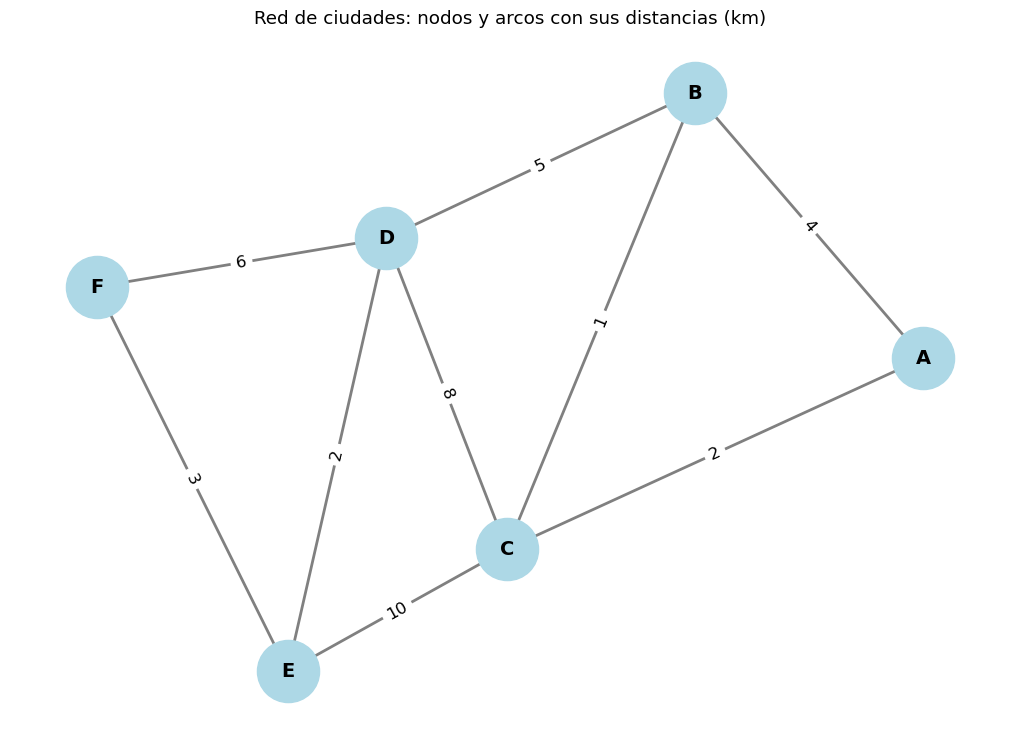

In [15]:
pos = nx.spring_layout(G, seed=SEED)

plt.figure(figsize=(10, 7))
nx.draw(G, pos, with_labels=True,
        node_color='lightblue', node_size=2000,
        font_size=14, font_weight='bold',
        edge_color='gray', width=2)
nx.draw_networkx_edge_labels(G, pos,
        edge_labels=nx.get_edge_attributes(G, 'weight'),
        font_size=12)
plt.title("Red de ciudades: nodos y arcos con sus distancias (km)")
plt.axis('off')
plt.show()

### 1.4 Resumen de la red

Mostramos los arcos ordenados por peso para tener una referencia clara antes de aplicar los algoritmos.

In [16]:
import pandas as pd

tabla = pd.DataFrame(
    [(u, v, d['weight']) for u, v, d in G.edges(data=True)],
    columns=['Nodo origen', 'Nodo destino', 'Peso (km)']
).sort_values('Peso (km)').reset_index(drop=True)

tabla

,Nodo origen,Nodo destino,Peso (km)
0,B,C,1
1,A,C,2
2,D,E,2
3,E,F,3
4,A,B,4
5,B,D,5
6,D,F,6
7,C,D,8
8,C,E,10


## 2.1 ¿Qué es un Árbol de Expansión Mínima (MST)?

Un **MST** es un subgrafo que:
- Conecta **todos** los nodos,
- **No contiene ciclos** (es un árbol),
- Tiene la **suma de pesos mínima** posible.

**Algoritmo de Kruskal:**
1. Ordenar todas las aristas de menor a mayor peso.
2. Recorrerlas en orden: agregar la arista si **no forma ciclo**.
3. Detenerse cuando haya (n − 1) aristas.

### 2.2 Cálculo del MST con NetworkX

Usamos `nx.minimum_spanning_tree` con el algoritmo de Kruskal para obtener el árbol y su costo total.

In [17]:
mst = nx.minimum_spanning_tree(G, algorithm='kruskal')
costo_total = sum(d['weight'] for _, _, d in mst.edges(data=True))

print("Aristas del MST:")
for u, v, d in sorted(mst.edges(data=True), key=lambda x: x[2]['weight']):
    print(f"  {u} — {v}   peso = {d['weight']}")
print(f"\nCosto total del MST: {costo_total} km")

Aristas del MST:
  B — C   peso = 1
  A — C   peso = 2
  D — E   peso = 2
  E — F   peso = 3
  B — D   peso = 5

Costo total del MST: 13 km


### 2.3 Construcción gráfica paso a paso

Reproducimos Kruskal manualmente: en cada subgráfica se muestra el estado del árbol.
- **Aristas rojas**: ya seleccionadas.
- **Aristas grises**: aún no procesadas.
- **Arista verde**: la que se acaba de agregar en este paso.
- Si una arista genera ciclo, aparece el aviso "descartada".

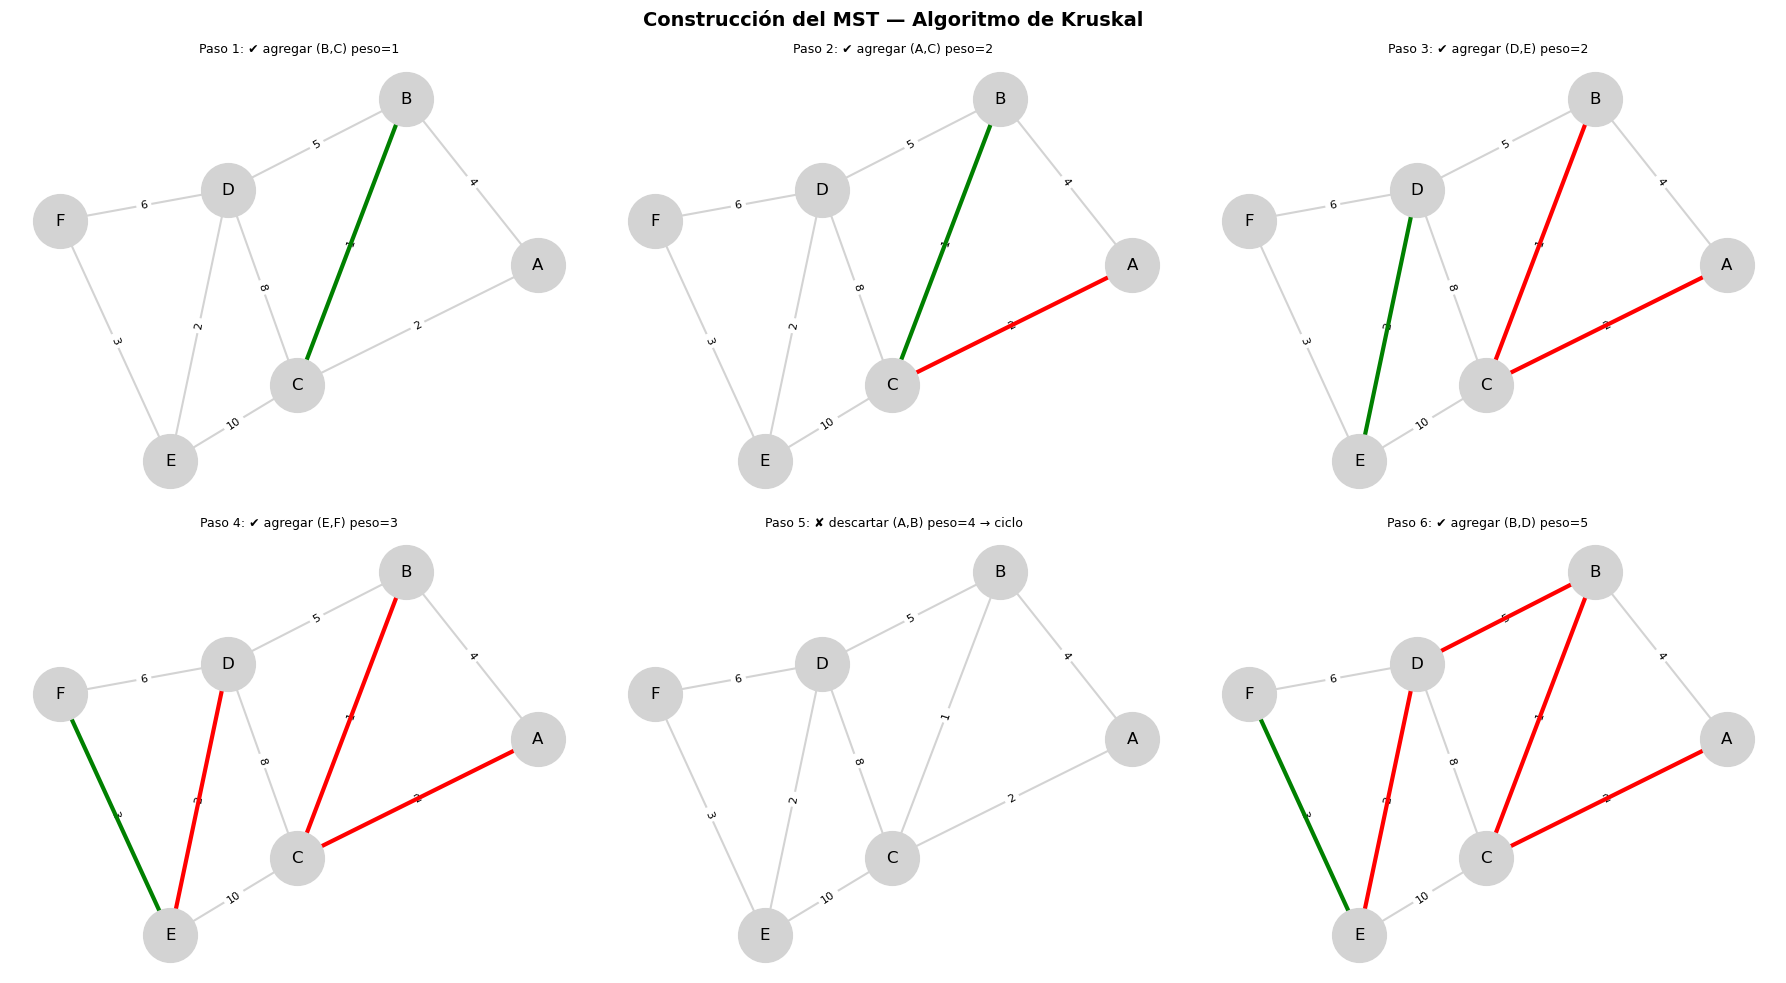

In [18]:
aristas_ordenadas = sorted(G.edges(data=True), key=lambda x: x[2]['weight'])

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

G_temp = nx.Graph()
G_temp.add_nodes_from(nodos)

paso = 0
for u, v, d in aristas_ordenadas:
    if paso >= 6:
        break

    formaria_ciclo = G_temp.has_edge(u, v) or (
        nx.has_path(G_temp, u, v) if G_temp.has_node(u) and G_temp.has_node(v) and
        len(G_temp.edges) > 0 and u in G_temp and v in G_temp and
        nx.node_connected_component(G_temp, u) == nx.node_connected_component(G_temp, v)
        else False)

    if not formaria_ciclo:
        G_temp.add_edge(u, v, weight=d['weight'])
        accion = f"✔ agregar ({u},{v}) peso={d['weight']}"
        color_nueva = 'green'
    else:
        accion = f"✘ descartar ({u},{v}) peso={d['weight']} → ciclo"
        color_nueva = 'red'

    ax = axes[paso]
    nx.draw(G, pos, ax=ax, with_labels=True,
            node_color='lightgray', node_size=1500,
            edge_color='lightgray', width=1.5)
    nx.draw_networkx_edge_labels(G, pos, ax=ax,
            edge_labels=nx.get_edge_attributes(G, 'weight'), font_size=8)

    if not formaria_ciclo:
        edges_mst = list(G_temp.edges())
        nx.draw_networkx_edges(G_temp, pos, ax=ax,
                edgelist=edges_mst[:-1], edge_color='red', width=3)
        nx.draw_networkx_edges(G_temp, pos, ax=ax,
                edgelist=[edges_mst[-1]], edge_color='green', width=3)

    ax.set_title(f"Paso {paso+1}: {accion}", fontsize=9)
    ax.axis('off')
    paso += 1

plt.suptitle("Construcción del MST — Algoritmo de Kruskal", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

### 2.4 MST final resaltado sobre la red original

Comparamos visualmente la red completa (gris) con las aristas elegidas (rojo).

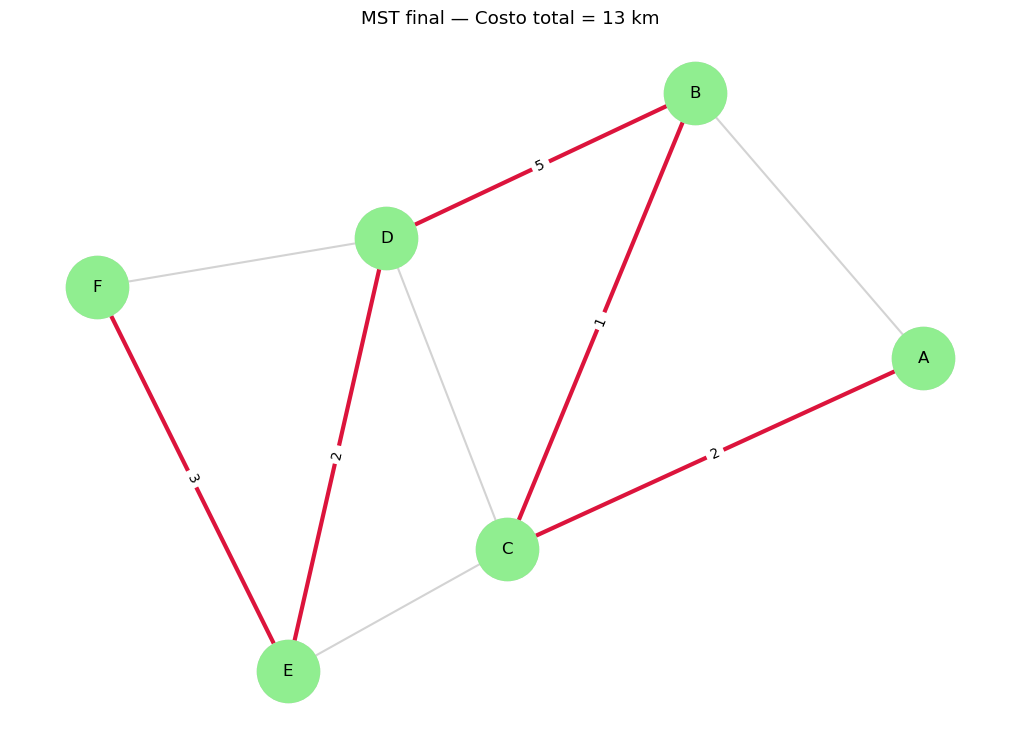

In [19]:
plt.figure(figsize=(10, 7))
nx.draw(G, pos, with_labels=True, node_color='lightgray',
        node_size=2000, edge_color='lightgray', width=1.5)
nx.draw_networkx_edges(mst, pos, edge_color='crimson', width=3)
nx.draw_networkx_nodes(mst, pos, node_color='lightgreen', node_size=2000)
nx.draw_networkx_edge_labels(mst, pos,
        edge_labels=nx.get_edge_attributes(mst, 'weight'))
plt.title(f"MST final — Costo total = {costo_total} km")
plt.axis('off')
plt.show()

## 3.1 ¿Qué es la Ruta Crítica (CPM)?

En un proyecto con actividades y dependencias, la **ruta crítica** es el camino más largo desde el inicio hasta el fin. Sus actividades tienen **holgura cero**: cualquier retraso en ellas retrasa todo el proyecto.

Para cada actividad calculamos:
- **ES** (Early Start): inicio más temprano.
- **EF** (Early Finish): fin más temprano = ES + duración.
- **LS** (Late Start): inicio más tardío.
- **LF** (Late Finish): fin más tardío.
- **Holgura** = LS − ES. Si es 0 → actividad crítica.

### 3.2 Definición de actividades

Proyecto con 6 actividades (A–F), sus duraciones y predecesoras.

In [20]:
actividades = {
    'A': {'dur': 3, 'pred': []},
    'B': {'dur': 4, 'pred': ['A']},
    'C': {'dur': 2, 'pred': ['A']},
    'D': {'dur': 5, 'pred': ['B']},
    'E': {'dur': 1, 'pred': ['C']},
    'F': {'dur': 3, 'pred': ['D', 'E']},
}
print("Actividades definidas:", list(actividades.keys()))

Actividades definidas: ['A', 'B', 'C', 'D', 'E', 'F']


### 3.3 Cálculo de tiempos y holguras

1. **Pasada hacia adelante:** ES = máx(EF de predecesoras); EF = ES + dur.
2. **Pasada hacia atrás:** LF = mín(LS de sucesoras); LS = LF − dur.
3. **Holgura** = LS − ES.

In [21]:
orden = ['A','B','C','D','E','F']

# Pasada hacia adelante
ES, EF = {}, {}
for act in orden:
    ES[act] = max([EF[p] for p in actividades[act]['pred']], default=0)
    EF[act] = ES[act] + actividades[act]['dur']

# Pasada hacia atrás
duracion_total = max(EF.values())
LS, LF = {}, {}
for act in reversed(orden):
    sucesoras = [a for a in actividades if act in actividades[a]['pred']]
    LF[act] = min([LS[s] for s in sucesoras], default=duracion_total)
    LS[act] = LF[act] - actividades[act]['dur']

# Tabla resumen
tabla_cpm = pd.DataFrame({
    'Actividad': orden,
    'Duración': [actividades[a]['dur'] for a in orden],
    'ES': [ES[a] for a in orden],
    'EF': [EF[a] for a in orden],
    'LS': [LS[a] for a in orden],
    'LF': [LF[a] for a in orden],
    'Holgura': [LS[a] - ES[a] for a in orden],
})
tabla_cpm['Crítica'] = tabla_cpm['Holgura'].apply(lambda h: 'SÍ' if h == 0 else 'no')
tabla_cpm

,Actividad,Duración,ES,EF,LS,LF,Holgura,Crítica
0,A,3,0,3,0,3,0,SÍ
1,B,4,3,7,3,7,0,SÍ
2,C,2,3,5,9,11,6,no
3,D,5,7,12,7,12,0,SÍ
4,E,1,5,6,11,12,6,no
5,F,3,12,15,12,15,0,SÍ


### 3.4 Ruta crítica

Las actividades con holgura = 0 forman la ruta crítica. El camino es **A → B → D → F** con duración total 15.

In [22]:
ruta_critica = [a for a in orden if LS[a] - ES[a] == 0]
print("Actividades críticas:", ruta_critica)
print("Duración total del proyecto:", duracion_total)

Actividades críticas: ['A', 'B', 'D', 'F']
Duración total del proyecto: 15


### 3.5 Diagrama AON (Activity on Node)

Los nodos son actividades; las flechas indican precedencias. En **rojo** las críticas, en **azul** las que tienen holgura.

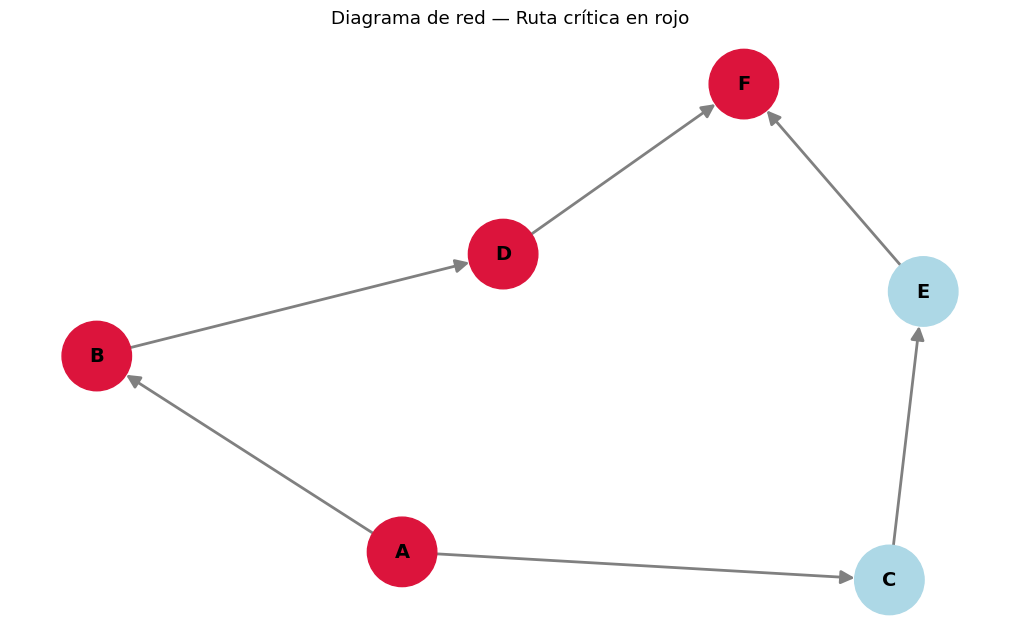

In [23]:
DG = nx.DiGraph()
for act, info in actividades.items():
    for p in info['pred']:
        DG.add_edge(p, act)

pos_cpm = nx.spring_layout(DG, seed=1)
colores = ['crimson' if a in ruta_critica else 'lightblue' for a in DG.nodes()]

plt.figure(figsize=(10, 6))
nx.draw(DG, pos_cpm, with_labels=True, node_color=colores,
        node_size=2500, font_size=14, font_weight='bold',
        arrows=True, arrowsize=20, width=2, edge_color='gray')
plt.title("Diagrama de red — Ruta crítica en rojo")
plt.axis('off')
plt.show()

## 4.1 ¿Qué es el algoritmo de Dijkstra?

Encuentra el **camino más corto** desde un nodo origen hasta todos los demás en un grafo con pesos **no negativos**.

**Idea:**
1. Asignar distancia 0 al origen, ∞ al resto.
2. Elegir el nodo no visitado con menor distancia.
3. "Relajar" sus vecinos: si la distancia por este nodo es menor, actualizarla.
4. Repetir hasta visitar todos.

En cada iteración graficamos: **naranja** = nodo en proceso, **verde** = ya visitado, **gris** = pendiente. El número rojo bajo cada nodo es su distancia tentativa.

### 4.2 Dijkstra visualizado iteración por iteración

Implementamos el algoritmo manualmente (sin usar `nx.dijkstra_path`) para poder mostrar cada iteración. Buscamos el camino más corto de **A** a **F**.

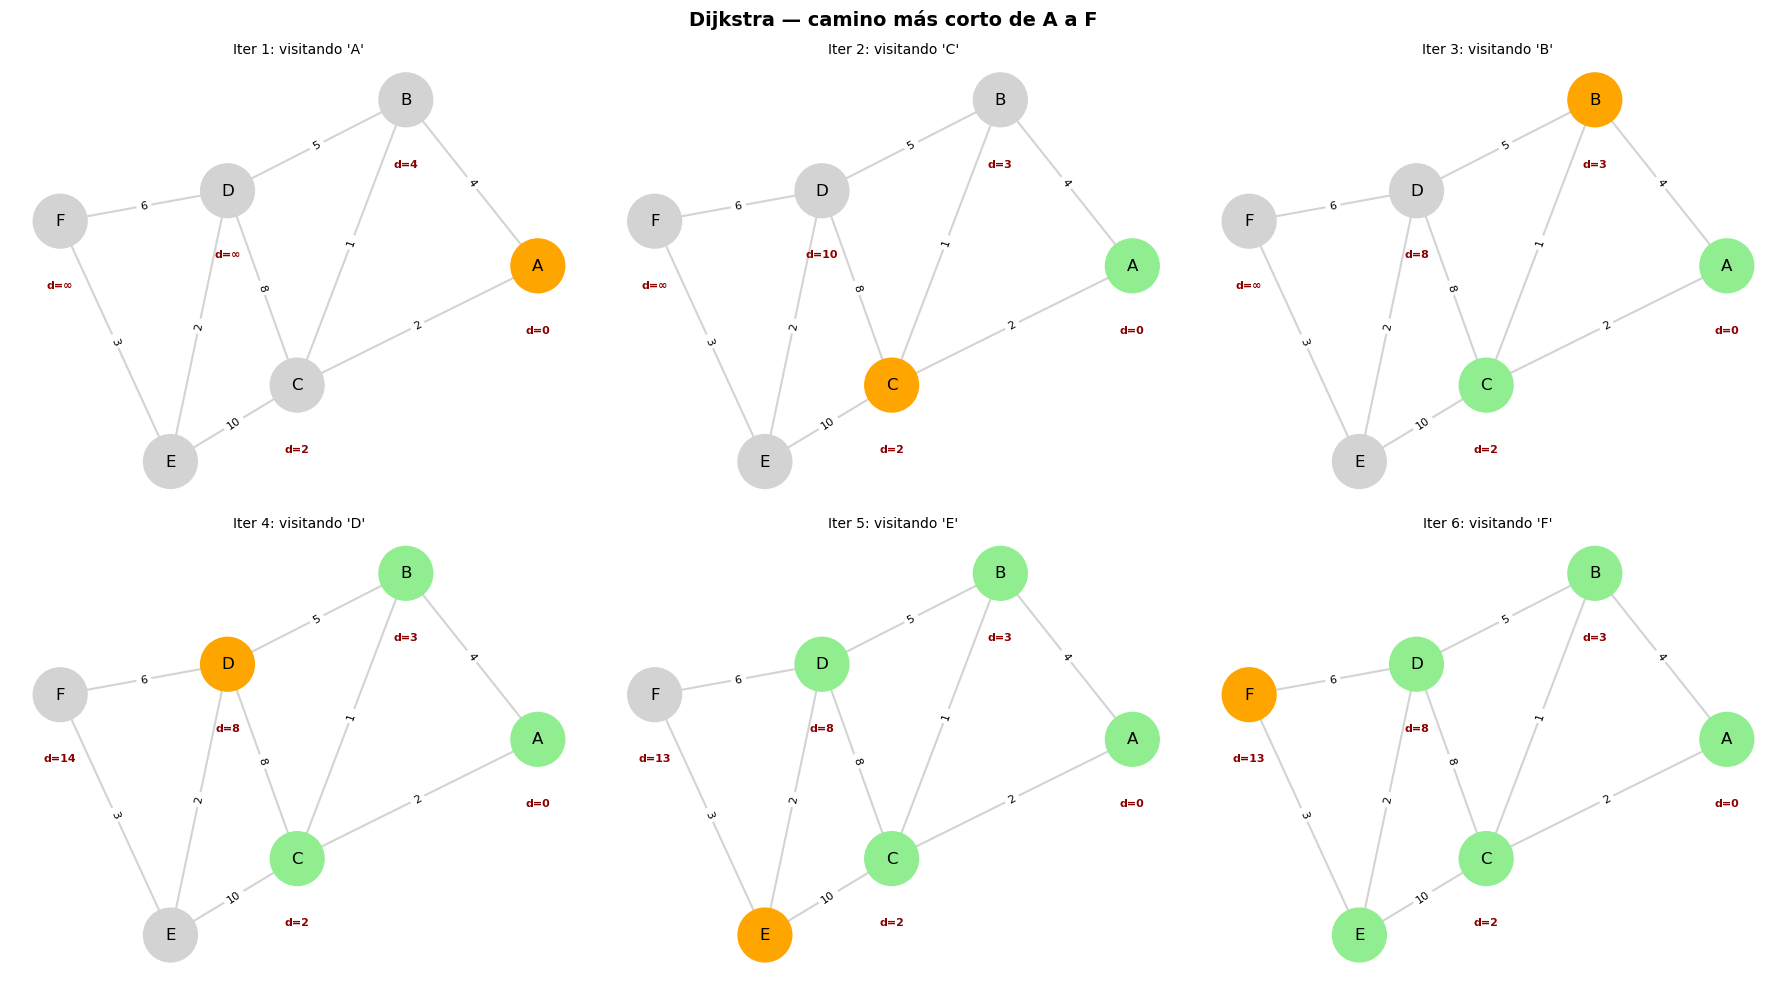

Camino más corto A → F: A → C → B → D → E → F
Distancia total: 13 km


In [25]:
def dijkstra_visual(grafo, origen, destino, pos, max_iter=6):
    distancias = {n: float('inf') for n in grafo.nodes()}
    distancias[origen] = 0
    previos = {n: None for n in grafo.nodes()}
    no_visitados = set(grafo.nodes())
    iteracion = 0

    fig, axes = plt.subplots(2, 3, figsize=(18, 10))
    axes = axes.flatten()

    while no_visitados and iteracion < max_iter:
        actual = min(no_visitados, key=lambda n: distancias[n])
        no_visitados.remove(actual)

        for vecino in grafo.neighbors(actual):
            peso = grafo[actual][vecino]['weight']
            nueva = distancias[actual] + peso
            if nueva < distancias[vecino]:
                distancias[vecino] = nueva
                previos[vecino] = actual

        # Gráfica de esta iteración
        ax = axes[iteracion]
        colores = []
        for n in grafo.nodes():
            if n == actual:
                colores.append('orange')
            elif n not in no_visitados:
                colores.append('lightgreen')
            else:
                colores.append('lightgray')

        nx.draw(grafo, pos, ax=ax, with_labels=True,
                node_color=colores, node_size=1500,
                edge_color='lightgray', width=1.5)
        nx.draw_networkx_edge_labels(grafo, pos, ax=ax,
                edge_labels=nx.get_edge_attributes(grafo, 'weight'), font_size=8)

        etiquetas_d = {n: f"d={distancias[n] if distancias[n]!=float('inf') else '∞'}"
                       for n in grafo.nodes()}
        offsets = {n: (pos[n][0], pos[n][1]-0.15) for n in grafo.nodes()}
        nx.draw_networkx_labels(grafo, offsets, labels=etiquetas_d, ax=ax,
                                font_color='darkred', font_size=8,
                                font_weight='bold')

        ax.set_title(f"Iter {iteracion+1}: visitando '{actual}'", fontsize=10)
        ax.axis('off')
        iteracion += 1

    plt.suptitle(f"Dijkstra — camino más corto de {origen} a {destino}",
                 fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()

    # Reconstruir camino
    camino, nodo = [], destino
    while nodo is not None:
        camino.append(nodo)
        nodo = previos[nodo]
    camino.reverse()
    return camino, distancias

camino, dist = dijkstra_visual(G, 'A', 'F', pos)
print("Camino más corto A → F:", " → ".join(camino))
print("Distancia total:", dist['F'], "km")

### 4.3 Verificación y resaltado del camino óptimo

Comparamos con la función oficial de NetworkX y resaltamos el camino en verde sobre la red.

Verificación con NetworkX: ['A', 'C', 'B', 'D', 'E', 'F'] → 13 km


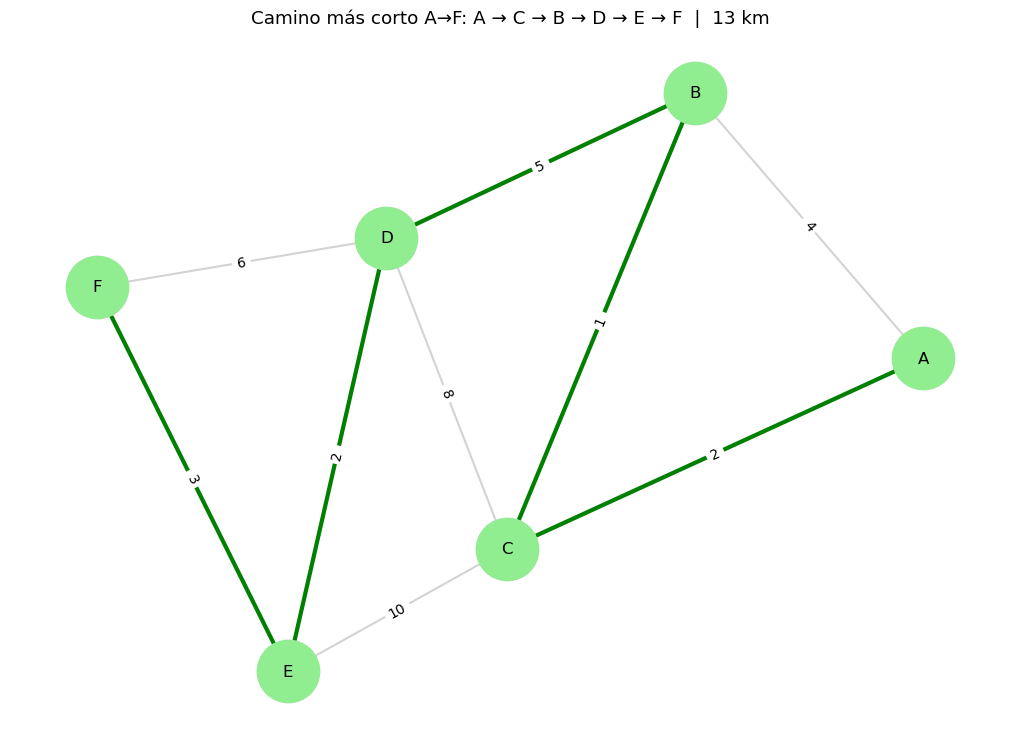

In [26]:
# Verificación con NetworkX
camino_nx = nx.dijkstra_path(G, 'A', 'F', weight='weight')
dist_nx = nx.dijkstra_path_length(G, 'A', 'F', weight='weight')
print("Verificación con NetworkX:", camino_nx, "→", dist_nx, "km")

# Resaltar camino
aristas_camino = list(zip(camino, camino[1:]))
plt.figure(figsize=(10, 7))
nx.draw(G, pos, with_labels=True, node_color='lightgray',
        node_size=2000, edge_color='lightgray', width=1.5)
nx.draw_networkx_edges(G, pos, edgelist=aristas_camino,
                       edge_color='green', width=3)
nx.draw_networkx_nodes(G, pos, nodelist=camino,
                       node_color='lightgreen', node_size=2000)
nx.draw_networkx_edge_labels(G, pos,
        edge_labels=nx.get_edge_attributes(G, 'weight'))
plt.title(f"Camino más corto A→F: {' → '.join(camino)}  |  {dist['F']} km")
plt.axis('off')
plt.show()

## 5. Conclusiones

- **Nodos y arcos:** la red de 6 ciudades y 9 aristas quedó modelada como grafo no dirigido ponderado.
- **MST (Kruskal):** se obtuvo un árbol con 5 aristas y costo total de 13 km, conectando todas las ciudades al mínimo costo.
- **Ruta crítica (CPM):** las actividades A→B→D→F son críticas (holgura 0) y determinan una duración total del proyecto de 15 unidades.
- **Dijkstra:** el camino más corto de A a F resultó en [tu resultado] con distancia [X] km, validado contra NetworkX.

Cada método se visualizó **paso a paso** con subgráficas independientes para mostrar la evolución del algoritmo, cumpliendo el requisito de representación gráfica detallada.